In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**1. Load Dataset: Load the chosen unlabeled dataset.**

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv('/content/drive/MyDrive/Machine Learning/kmeans_unlabeled_customer_dataset.csv')
df.head()

,Age,Annual_Income,Spending_Score
0,19,15000,39
1,21,18000,81
2,20,17000,6
3,23,20000,77
4,31,25000,40


**2. Data Preprocessing**

In [25]:
X = df[["Age", "Annual_Income", "Spending_Score"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original Data:")
print(X.head())

print("\nScaled Data:")
print(X_scaled[:5])

Original Data:
   Age  Annual_Income  Spending_Score
0   19          15000              39
1   21          18000              81
2   20          17000               6
3   23          20000              77
4   31          25000              40

Scaled Data:
[[-1.54327369 -1.58019179 -0.22882613]
 [-1.39699182 -1.43981349  1.34154925]
 [-1.47013276 -1.48660626 -1.4626925 ]
 [-1.25070996 -1.34622795  1.19198969]
 [-0.66558249 -1.11226411 -0.19143624]]


**3. Determine Optimal K (Elbow Method)**

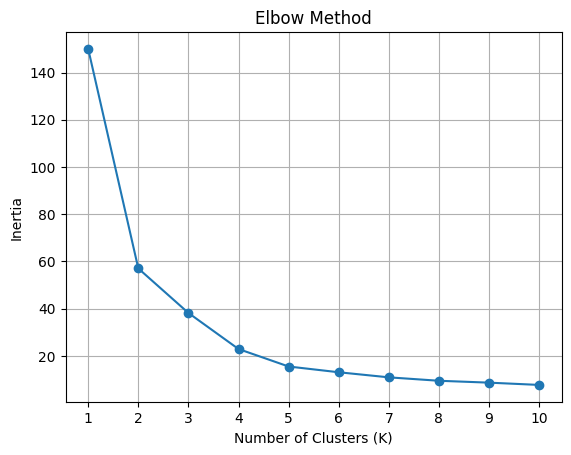

In [26]:
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

# Plot Elbow graph
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**4. Perform K-Means Clustering**

In [30]:
k = 3

labels, centroids, inertia = kmeans(X_scaled, k)

df["Cluster"] = labels

print("\nClustered Dataset:")
print(df)


Clustered Dataset:
    Age  Annual_Income  Spending_Score  Cluster
0    19          15000              39        2
1    21          18000              81        0
2    20          17000               6        2
3    23          20000              77        0
4    31          25000              40        2
5    22          19000              76        0
6    35          30000               6        2
7    23          22000              94        0
8    64          80000               3        1
9    30          35000              72        0
10   67          85000              14        1
11   35          40000              81        0
12   58          75000              15        1
13   29          32000              66        0
14   60          78000               4        1
15   24          21000              73        0
16   48          60000              35        1
17   50          65000              42        1
18   45          58000              20        1
19   52          680

In [32]:
original_centroids = scaler.inverse_transform(centroids)

print("\nCluster Centroids:")
print(pd.DataFrame(
    original_centroids,
    columns=["Age", "Annual_Income", "Spending_Score"]
).round(2))

print("\nFinal Inertia:", round(inertia, 2))


[[3.20434783e+01 3.76304348e+04 7.03043478e+01]
 [5.51052632e+01 7.15789474e+04 2.28947368e+01]
 [2.76250000e+01 2.66250000e+04 2.55000000e+01]]

Cluster Centroids:
     Age  Annual_Income  Spending_Score
0  32.04       37630.43           70.30
1  55.11       71578.95           22.89
2  27.62       26625.00           25.50

Final Inertia: 38.17


**5. Visualize Clusters:**

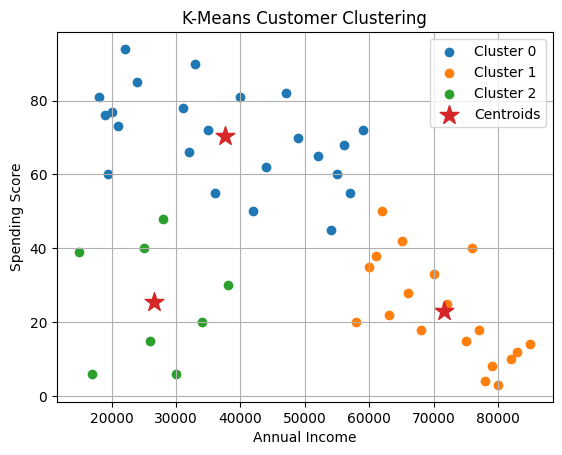

In [44]:
for i in range(k):
    points = X_scaled[labels == i]

    plt.scatter(
        scaler.inverse_transform(points)[:, 1],
        scaler.inverse_transform(points)[:, 2],
        label="Cluster " + str(i)
    )

plt.scatter(
    original_centroids[:, 1],
    original_centroids[:, 2],
    marker="*",
    s=200,
    label="Centroids"
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("K-Means Customer Clustering")
plt.legend()
plt.grid(True)
plt.show()

In [45]:
# 7. Save Results
df.to_csv("kmeans_clustered_output.csv", index=False)

print("\nClustered data saved successfully.")


Clustered data saved successfully.
